In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Data Understanding

In [2]:
df = pd.read_csv('D:\Coding\Bleep\Resources\online-shopping\e-shop-clothing-2008.csv', sep=';')

<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_19628\812310395.py:1: SyntaxWarning: invalid escape sequence '\C'
  df = pd.read_csv('D:\Coding\Bleep\Resources\online-shopping\e-shop-clothing-2008.csv', sep=';')


In [3]:
df.head()

,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


In [4]:
df = df.rename(columns={
    "session ID": "session_id", "page 1 (main category)": "category",
    "page 2 (clothing model)": "model", "model photography": "photo",
    "price 2": "price_above_avg", "page": "page_no"})
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165474 entries, 0 to 165473
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   year             165474 non-null  int64 
 1   month            165474 non-null  int64 
 2   day              165474 non-null  int64 
 3   order            165474 non-null  int64 
 4   country          165474 non-null  int64 
 5   session_id       165474 non-null  int64 
 6   category         165474 non-null  int64 
 7   model            165474 non-null  object
 8   colour           165474 non-null  int64 
 9   location         165474 non-null  int64 
 10  photo            165474 non-null  int64 
 11  price            165474 non-null  int64 
 12  price_above_avg  165474 non-null  int64 
 13  page_no          165474 non-null  int64 
dtypes: int64(13), object(1)
memory usage: 17.7+ MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,165474.0,2008.000000,0.000000,2008.0,2008.0,2008.0,2008.0,2008.0
month,165474.0,5.585887,1.328160,4.0,4.0,5.0,7.0,8.0
day,165474.0,14.524554,8.830374,1.0,7.0,14.0,22.0,31.0
order,165474.0,9.817476,13.478411,1.0,2.0,6.0,12.0,195.0
country,165474.0,26.952621,7.150691,1.0,29.0,29.0,29.0,47.0
session_id,165474.0,12058.417056,7008.418903,1.0,5931.0,11967.5,18219.0,24026.0
category,165474.0,2.400842,1.144420,1.0,1.0,2.0,3.0,4.0
colour,165474.0,6.227655,4.235606,1.0,3.0,4.0,9.0,14.0
location,165474.0,3.258198,1.713206,1.0,2.0,3.0,5.0,6.0
photo,165474.0,1.260071,0.438674,1.0,1.0,1.0,2.0,2.0


# Data Cleaning

In [6]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Constant columns:", [c for c in df if df[c].nunique() == 1])

Missing values: 0
Duplicate rows: 0
Constant columns: ['year']


In [7]:
CAT = {1: "Trousers", 2: "Skirts", 3: "Blouses", 4: "Sale"}
COLOUR = {1: "beige", 2: "black", 3: "blue", 4: "brown", 5: "burgundy", 6: "gray", 7: "green",
          8: "navy blue", 9: "multicolor", 10: "olive", 11: "pink", 12: "red", 13: "violet", 14: "white"}
LOC = {1: "top left", 2: "top middle", 3: "top right", 4: "bottom left", 5: "bottom middle", 6: "bottom right"}
COUNTRY = {1: "Australia", 2: "Austria", 3: "Belgium", 4: "British Virgin Is.", 5: "Cayman Is.",
           6: "Christmas Is.", 7: "Croatia", 8: "Cyprus", 9: "Czech Republic", 10: "Denmark",
           11: "Estonia", 12: "unidentified", 13: "Faroe Is.", 14: "Finland", 15: "France",
           16: "Germany", 17: "Greece", 18: "Hungary", 19: "Iceland", 20: "India", 21: "Ireland",
           22: "Italy", 23: "Latvia", 24: "Lithuania", 25: "Luxembourg", 26: "Mexico",
           27: "Netherlands", 28: "Norway", 29: "Poland", 30: "Portugal", 31: "Romania",
           32: "Russia", 33: "San Marino", 34: "Slovakia", 35: "Slovenia", 36: "Spain",
           37: "Sweden", 38: "Switzerland", 39: "Ukraine", 40: "UAE", 41: "UK", 42: "USA",
           43: ".biz", 44: ".com", 45: ".int", 46: ".net", 47: ".org"}

df["date"] = pd.to_datetime(dict(year=df.year, month=df.month, day=df.day))
df["weekday"] = df.date.dt.day_name()
df["category_name"] = df.category.map(CAT)
df["colour_name"] = df.colour.map(COLOUR)
df["location_name"] = df.location.map(LOC)
df["country_name"] = df.country.map(COUNTRY)
df["photo_name"] = df.photo.map({1: "en face", 2: "profile"})
df["price_above_avg"] = (df.price_above_avg == 1)      # recode 1/2 -> True/False
print("Unmapped codes:", df[["category_name", "colour_name", "location_name", "country_name"]].isna().sum().sum())

Unmapped codes: 0


In [8]:
# checking whether the mapping was consistent or not throughtout.
prefix = df.model.str[0].map({"A": 1, "B": 2, "C": 3, "P": 4})
print("Rows where model prefix disagrees with category:", int((prefix != df.category).sum()))
print("Models with more than one price:", int((df.groupby("model").price.nunique() > 1).sum()))
cat_avg = df.drop_duplicates("model").groupby("category").price.mean()
print("Mean price when flagged above-average vs below:", df.groupby("price_above_avg").price.mean().round(1).to_dict())
sess = df.groupby("session_id")
print("Sessions with >1 country:", int((sess.country.nunique() > 1).sum()),
      "| clicks where order != 1..n:", int((sess["order"].max() != sess.size()).sum()))
print("Date range:", df.date.min().date(), "to", df.date.max().date())

Rows where model prefix disagrees with category: 1
Models with more than one price: 0
Mean price when flagged above-average vs below: {False: 34.2, True: 52.9}
Sessions with >1 country: 0 | clicks where order != 1..n: 0
Date range: 2008-04-01 to 2008-08-13


# Exploratory Analysis


--- CATEGORICAL VARIABLE ANALYSIS ---
Top 5 Countries by clicks:
country_name
Poland            133963
Czech Republic     18003
Lithuania           4091
.net                2522
.com                1385
Name: count, dtype: int64

Clicks by Category:
category_name
Trousers    49742
Sale        38747
Blouses     38577
Skirts      38408
Name: count, dtype: int64


C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_19628\712887065.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='category_name', order=df['category_name'].value_counts().index, palette='viridis')
C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_19628\712887065.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='colour_name', order=df['colour_name'].value_counts().index[:10], palette='viridis')
C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_19628\712887065.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.

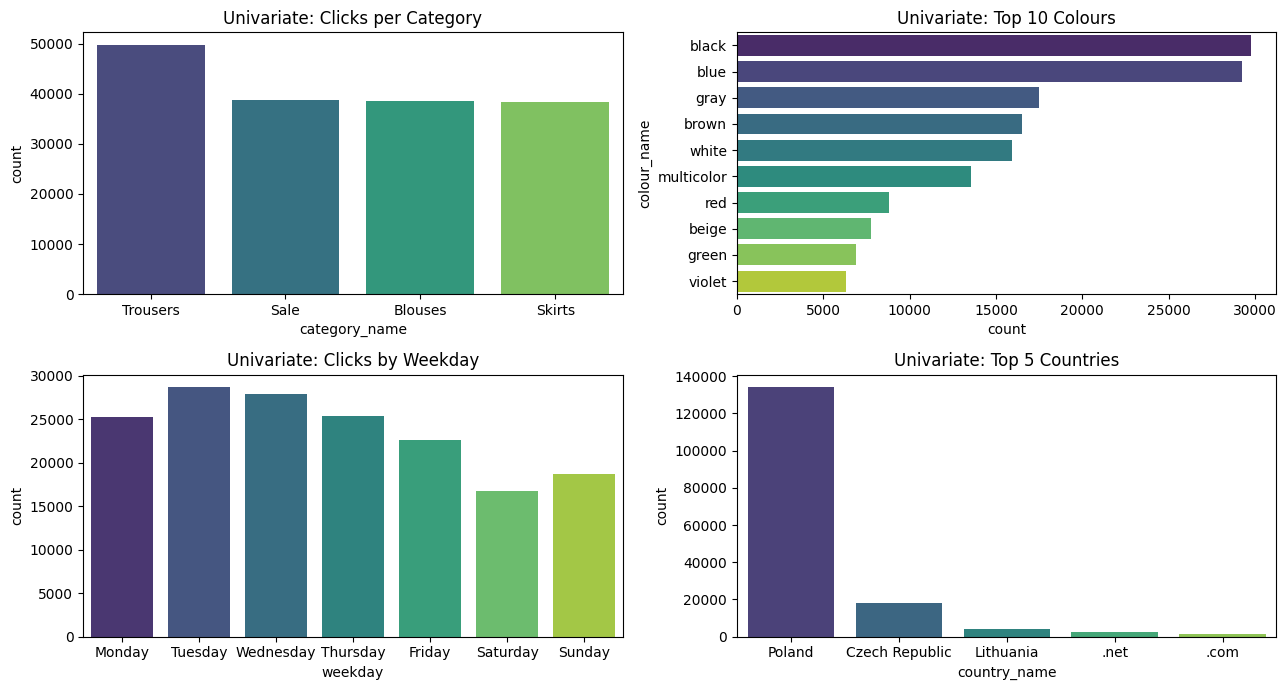

In [9]:
# Categorical aur Univariant Analysis of data
print("\n--- CATEGORICAL VARIABLE ANALYSIS ---")
print("Top 5 Countries by clicks:")
print(df['country_name'].value_counts().head())
print("\nClicks by Category:")
print(df['category_name'].value_counts())

plt.figure(figsize=(13, 7))
plt.subplot(2, 2, 1)
sns.countplot(data=df, x='category_name', order=df['category_name'].value_counts().index, palette='viridis')
plt.title('Univariate: Clicks per Category')

plt.subplot(2, 2, 2)
sns.countplot(data=df, y='colour_name', order=df['colour_name'].value_counts().index[:10], palette='viridis')
plt.title('Univariate: Top 10 Colours')

plt.subplot(2, 2, 3)
sns.countplot(data=df, x='weekday', order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], palette='viridis')
plt.title('Univariate: Clicks by Weekday')

plt.subplot(2, 2, 4)
top_countries = df['country_name'].value_counts().index[:5]
sns.countplot(data=df[df['country_name'].isin(top_countries)], x='country_name', order=top_countries, palette='viridis')
plt.title('Univariate: Top 5 Countries')

plt.tight_layout()
plt.savefig('categorical.png')
plt.show()
plt.close()

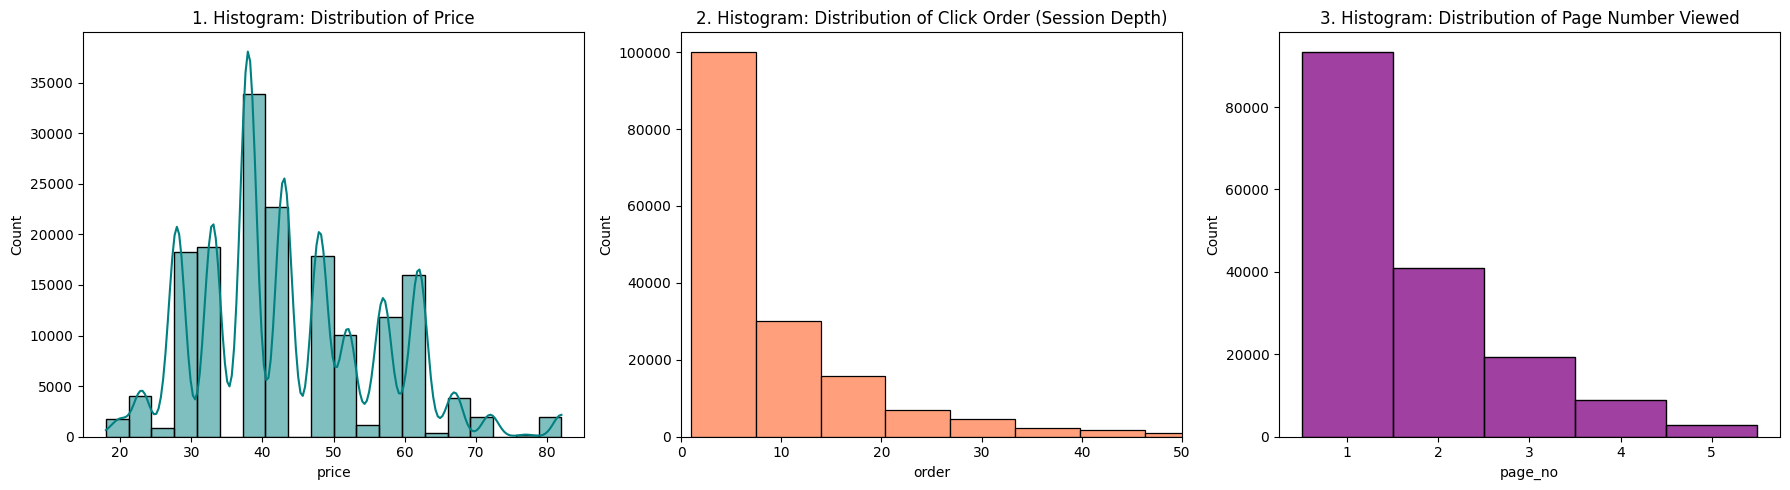

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df['price'], bins=20, kde=True, ax=axes[0], color='teal')
axes[0].set_title('1. Histogram: Distribution of Price')

sns.histplot(df['order'], bins=30, kde=False, ax=axes[1], color='coral')
axes[1].set_title('2. Histogram: Distribution of Click Order (Session Depth)')
axes[1].set_xlim(0, 50) # Zoomed in for visibility due to long tail

sns.histplot(df['page_no'], bins=5, discrete=True, ax=axes[2], color='purple')
axes[2].set_title('3. Histogram: Distribution of Page Number Viewed')
plt.tight_layout()
plt.show()

C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_19628\580493963.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='category_name', y='price', ax=axes[0], palette='Set2')
C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_19628\580493963.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='location_name', y='price', ax=axes[1], palette='Set3')
C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_19628\580493963.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='weekday', y='order', order=['Monday', 'Tuesd

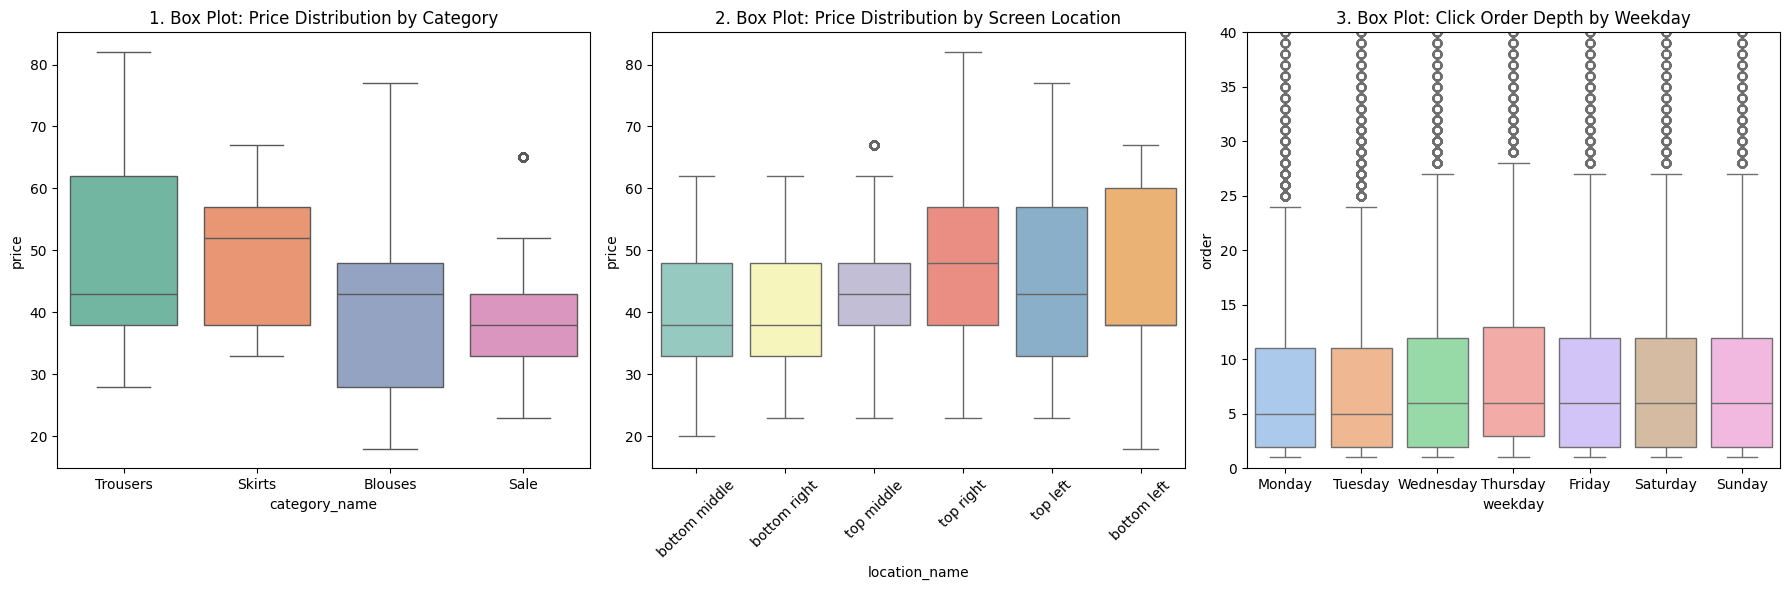

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
sns.boxplot(data=df, x='category_name', y='price', ax=axes[0], palette='Set2')
axes[0].set_title('1. Box Plot: Price Distribution by Category')

sns.boxplot(data=df, x='location_name', y='price', ax=axes[1], palette='Set3')
axes[1].set_title('2. Box Plot: Price Distribution by Screen Location')
axes[1].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='weekday', y='order', order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], ax=axes[2], palette='pastel')
axes[2].set_title('3. Box Plot: Click Order Depth by Weekday')
axes[2].set_ylim(0, 40)
plt.tight_layout()
plt.show()

C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_19628\1810112269.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df[df['country_name'].isin(top_countries)], x='country_name', y='price', ax=axes[0], palette='magma')
C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_19628\1810112269.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='category_name', y='page_no', ax=axes[1], palette='viridis')
C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_19628\1810112269.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df

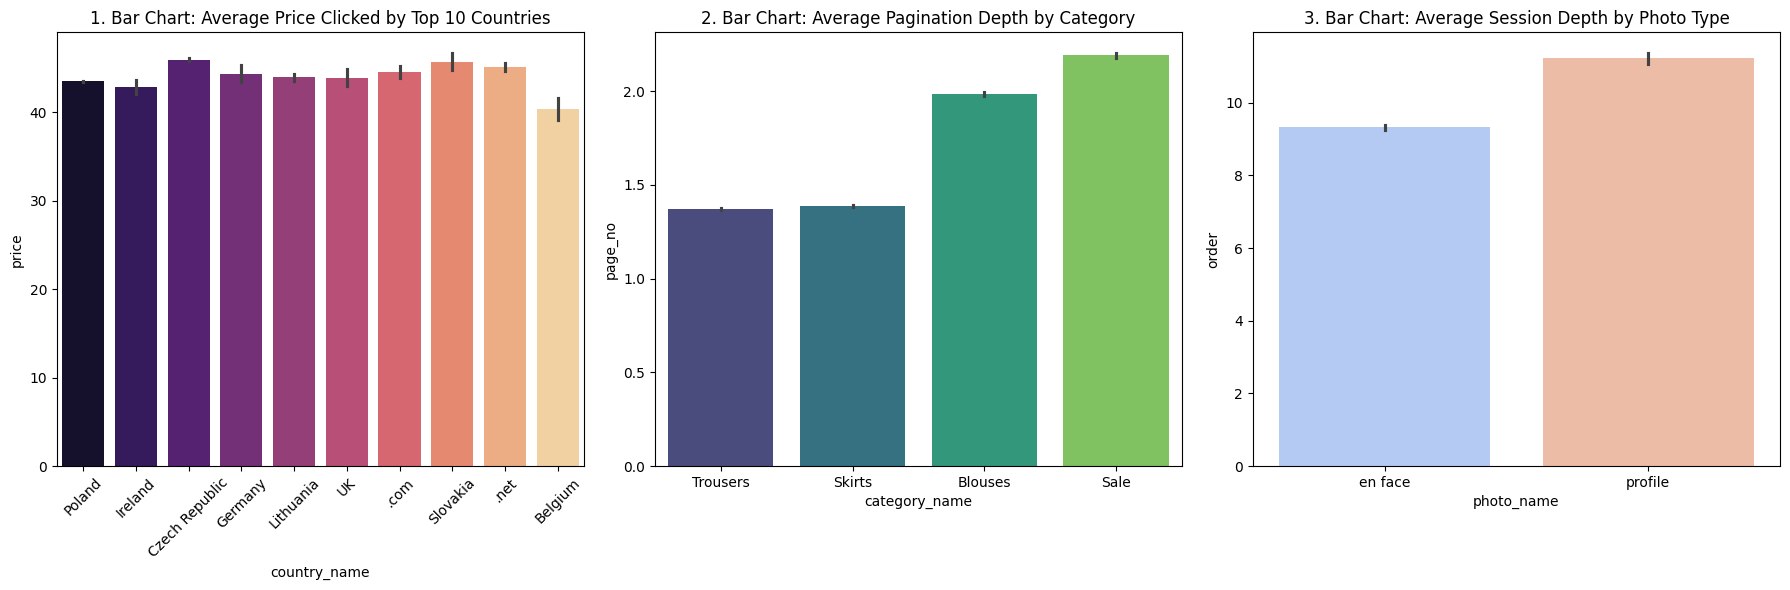

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
top_countries = df['country_name'].value_counts().nlargest(10).index
sns.barplot(data=df[df['country_name'].isin(top_countries)], x='country_name', y='price', ax=axes[0], palette='magma')
axes[0].set_title('1. Bar Chart: Average Price Clicked by Top 10 Countries')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(data=df, x='category_name', y='page_no', ax=axes[1], palette='viridis')
axes[1].set_title('2. Bar Chart: Average Pagination Depth by Category')

sns.barplot(data=df, x='photo_name', y='order', ax=axes[2], palette='coolwarm')
axes[2].set_title('3. Bar Chart: Average Session Depth by Photo Type')
plt.tight_layout()
plt.show()

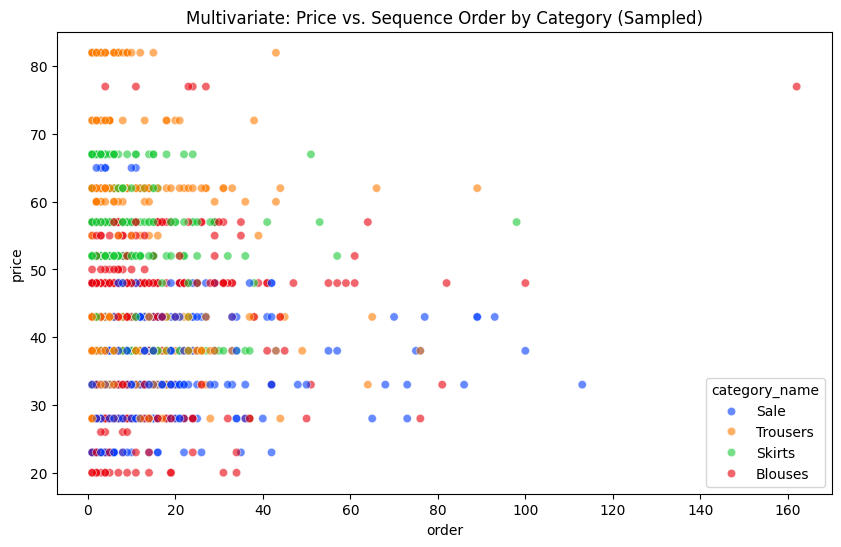

In [13]:
#Multivariate Analysis
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df.sample(2000, random_state=42), x='order', y='price', hue='category_name', alpha=0.6, palette='bright')
plt.title('Multivariate: Price vs. Sequence Order by Category (Sampled)')
plt.savefig('multivariate.png')
plt.show()
plt.close()


--- CORRELATION ANALYSIS ---
            price     order   page_no     month       day
price    1.000000 -0.064779 -0.150455  0.012700 -0.002818
order   -0.064779  1.000000  0.204106  0.026093 -0.021744
page_no -0.150455  0.204106  1.000000  0.020898  0.011125
month    0.012700  0.026093  0.020898  1.000000 -0.075098
day     -0.002818 -0.021744  0.011125 -0.075098  1.000000


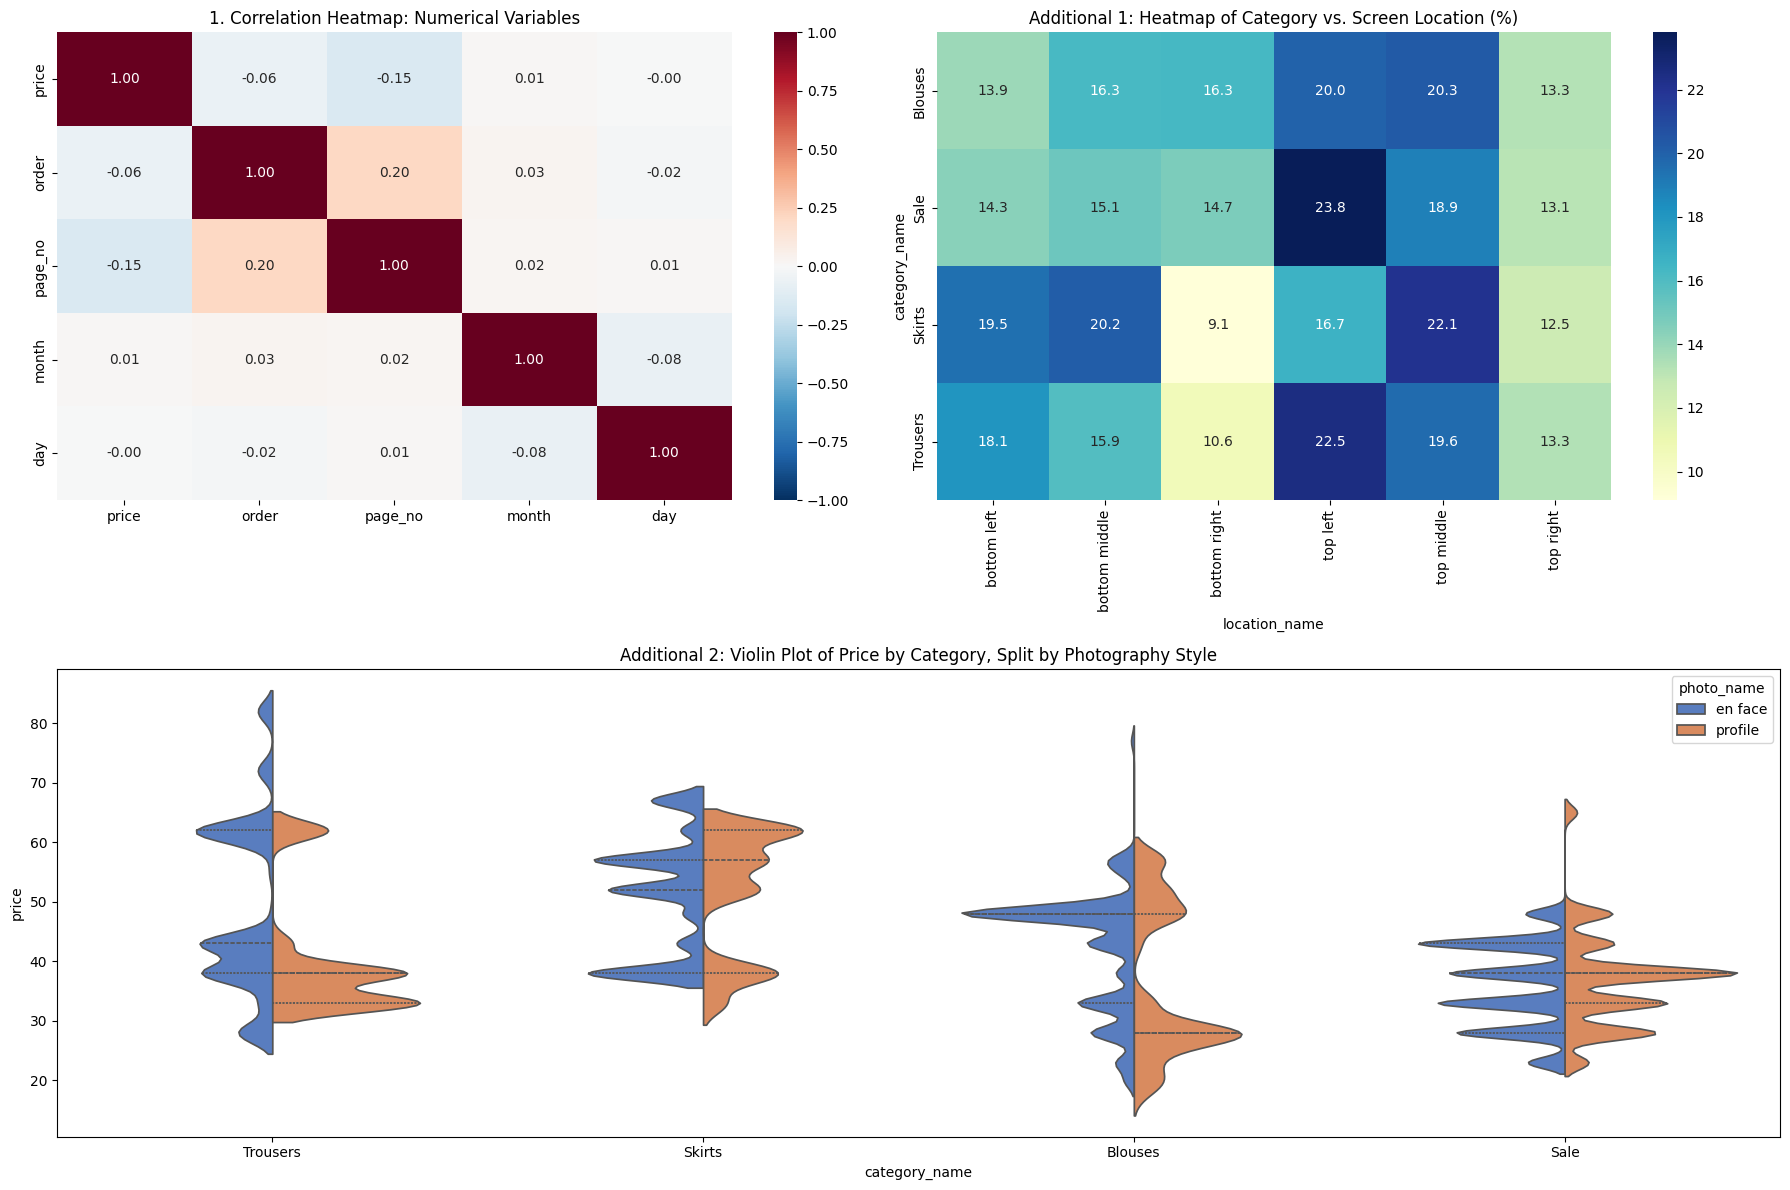

In [14]:
# Correlation Analysis
print("\n--- CORRELATION ANALYSIS ---")
corr_matrix = df[['price', 'order', 'page_no', 'month', 'day']].corr()
print(corr_matrix)

fig = plt.figure(figsize=(18, 12))

# Subplot 1: Correlation Heatmap
ax1 = fig.add_subplot(2, 2, 1)
corr_cols = ['price', 'order', 'page_no', 'month', 'day']
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='RdBu_r', vmin=-1, vmax=1, fmt=".2f", ax=ax1)
ax1.set_title('1. Correlation Heatmap: Numerical Variables')

# Subplot 2: Heatmap of Category vs. Location on Screen
ax2 = fig.add_subplot(2, 2, 2)
crosstab_cat_loc = pd.crosstab(df['category_name'], df['location_name'], normalize='index') * 100
sns.heatmap(crosstab_cat_loc, annot=True, cmap='YlGnBu', fmt=".1f", ax=ax2)
ax2.set_title('Additional 1: Heatmap of Category vs. Screen Location (%)')

# Subplot 3: Violin Plot of Price by Photo Type
ax3 = fig.add_subplot(2, 1, 2)
sns.violinplot(data=df, x='category_name', y='price', hue='photo_name', split=True, inner="quart", ax=ax3, palette='muted')
ax3.set_title('Additional 2: Violin Plot of Price by Category, Split by Photography Style')

plt.tight_layout()
plt.savefig('req_heatmap_extras.png')
plt.show()

--- NUMERICAL VARIABLE ANALYSIS ---
               price          order        page_no
count  165474.000000  165474.000000  165474.000000
mean       43.802507       9.817476       1.710166
std        12.548131      13.478411       0.982412
min        18.000000       1.000000       1.000000
25%        33.000000       2.000000       1.000000
50%        43.000000       6.000000       1.000000
75%        52.000000      12.000000       2.000000
max        82.000000     195.000000       5.000000


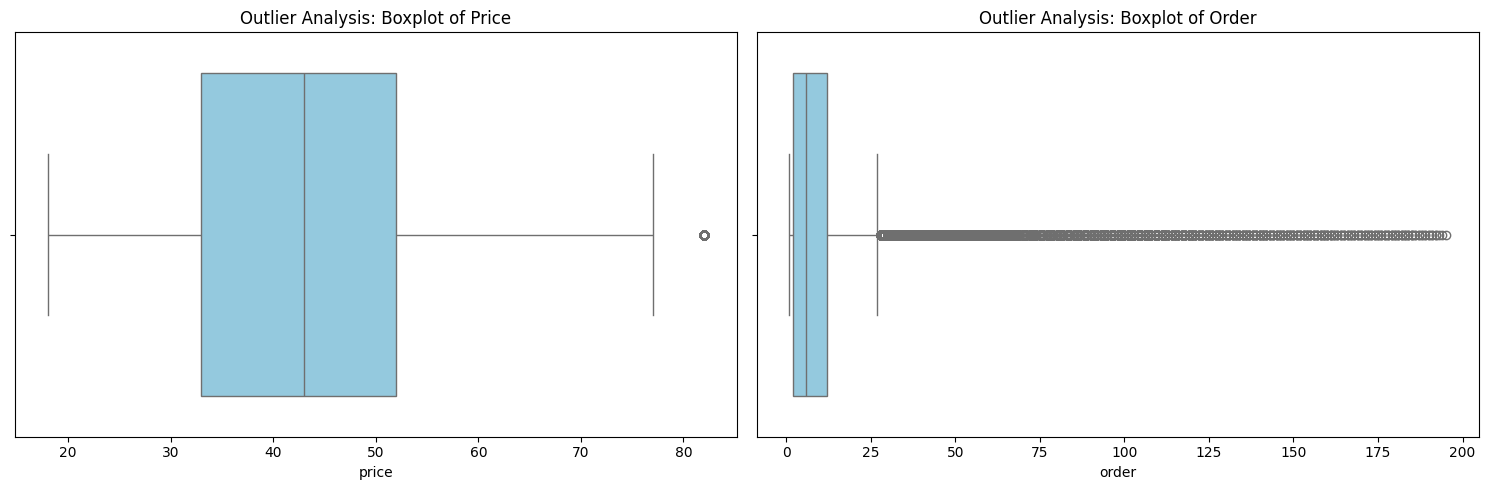

In [15]:
# Numerical Analysis & Outlier Analysis
print("--- NUMERICAL VARIABLE ANALYSIS ---")
num_cols = ['price', 'order', 'page_no']
print(df[num_cols].describe())

plt.figure(figsize=(15, 5))
for i, col in enumerate(['price', 'order'], 1):
    plt.subplot(1, 2, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Outlier Analysis: Boxplot of {col.capitalize()}')
plt.tight_layout()

plt.show()
plt.close()

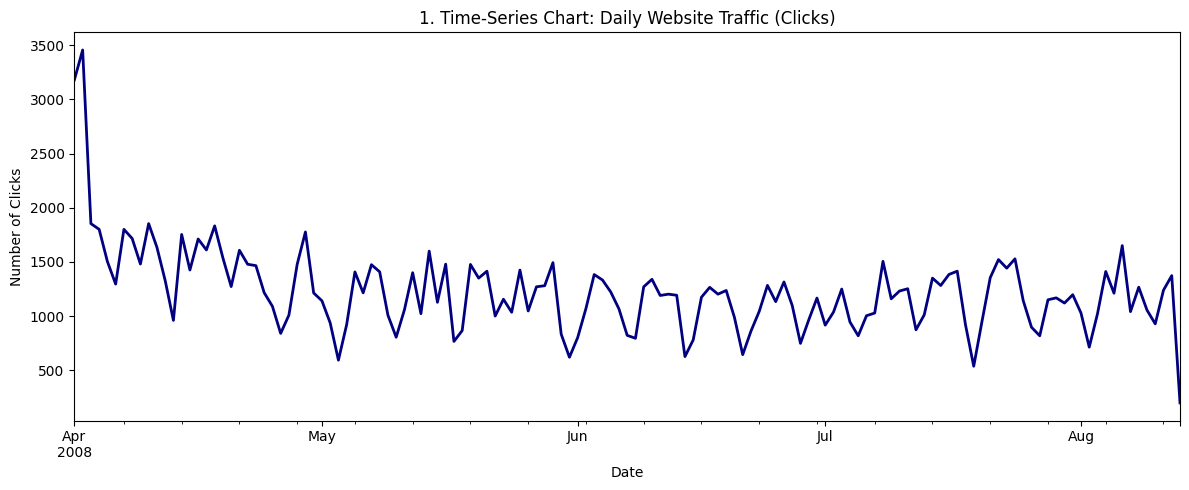

In [16]:
plt.figure(figsize=(12, 5))
daily_traffic = df.groupby('date').size()
daily_traffic.plot(color='navy', linewidth=2)
plt.title('1. Time-Series Chart: Daily Website Traffic (Clicks)')
plt.xlabel('Date')
plt.ylabel('Number of Clicks')
plt.tight_layout()
plt.show()